# ML Lab-9
## Name :- Jaheed Pathan
## Roll no :- 53
## Section :- A-A4

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize']=(8,5)

df = pd.read_csv("Wholesale customers data.csv")


features = [col for col in df.columns if col not in ['Channel', 'Region']]
X = df[features]

In [ ]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [ ]:
X_scaled_df=pd.DataFrame(X_scaled,columns=features,index=X.index)

In [ ]:
print("First five scaled records:")
display(X_scaled_df.head())

First five scaled records:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [ ]:
print("\nScaled feature means")
print(X_scaled_df.mean())
print("\nScaled feature standard deviations")
print(X_scaled_df.std())


Scaled feature means
Fresh              -3.431598e-17
Milk                0.000000e+00
Grocery            -4.037175e-17
Frozen              3.633457e-17
Detergents_Paper    2.422305e-17
Delicassen         -8.074349e-18
dtype: float64

Scaled feature standard deviations
Fresh               1.001138
Milk                1.001138
Grocery             1.001138
Frozen              1.001138
Detergents_Paper    1.001138
Delicassen          1.001138
dtype: float64


## Calculate WCSS

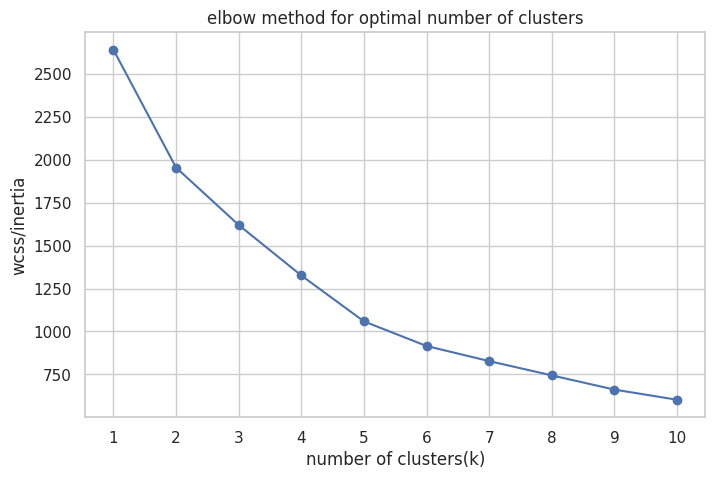

In [ ]:
wcss=[]
k_values=range(1,11)
for k in k_values:
  kmeans=KMeans(n_clusters=k,random_state=123,n_init=10)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(k_values),wcss,marker="o")
plt.title("elbow method for optimal number of clusters")
plt.xlabel("number of clusters(k)")
plt.ylabel("wcss/inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

## Calculate silhouette scores to support the elbow decision


In [ ]:
silhouette_values=[]
for k in range(2,11):
  model=KMeans(n_clusters=k,random_state=42,n_init=10)
  labels=model.fit_predict(X_scaled)
  score=silhouette_score(X_scaled,labels)
  silhouette_values.append(score)
silhouette_table=pd.DataFrame({
    "number of clusters (k)":range(2,11),
    "silhouette score":silhouette_values
})
display(silhouette_table.round(4))

,number of clusters (k),silhouette score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [ ]:
suggested_k=int(
    silhouette_table.loc[silhouette_table["silhouette score"].idxmax(),"number of clusters (k)"]
)
print("k suggested by the highest silhouette score:",suggested_k)

k suggested by the highest silhouette score: 3


In [ ]:
k=suggested_k
kmeans_model=KMeans(n_clusters=k,random_state=42,n_init=10)
kmeans_labels=kmeans_model.fit_predict(X_scaled)

In [ ]:
df_kmeans=df.copy()
df_kmeans["KMeans_Cluster"]=kmeans_labels
print("KMeans clustering completed")
print("\nNumber of customers in each cluster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

KMeans clustering completed

Number of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64


In [ ]:
hierarchical_model=AgglomerativeClustering(n_clusters=k,linkage="ward",metric="euclidean")
hierarchical_labels=hierarchical_model.fit_predict(X_scaled)

In [ ]:
df_hierarchical=df.copy()
df_hierarchical["hierarchical_cluster"] = hierarchical_labels
print("\nnumber of customers in each cluster:")
print(df_hierarchical["hierarchical_cluster"].value_counts().sort_index())
display(df_hierarchical.head())


number of customers in each cluster:
hierarchical_cluster
0      6
1    281
2    153
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,hierarchical_cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


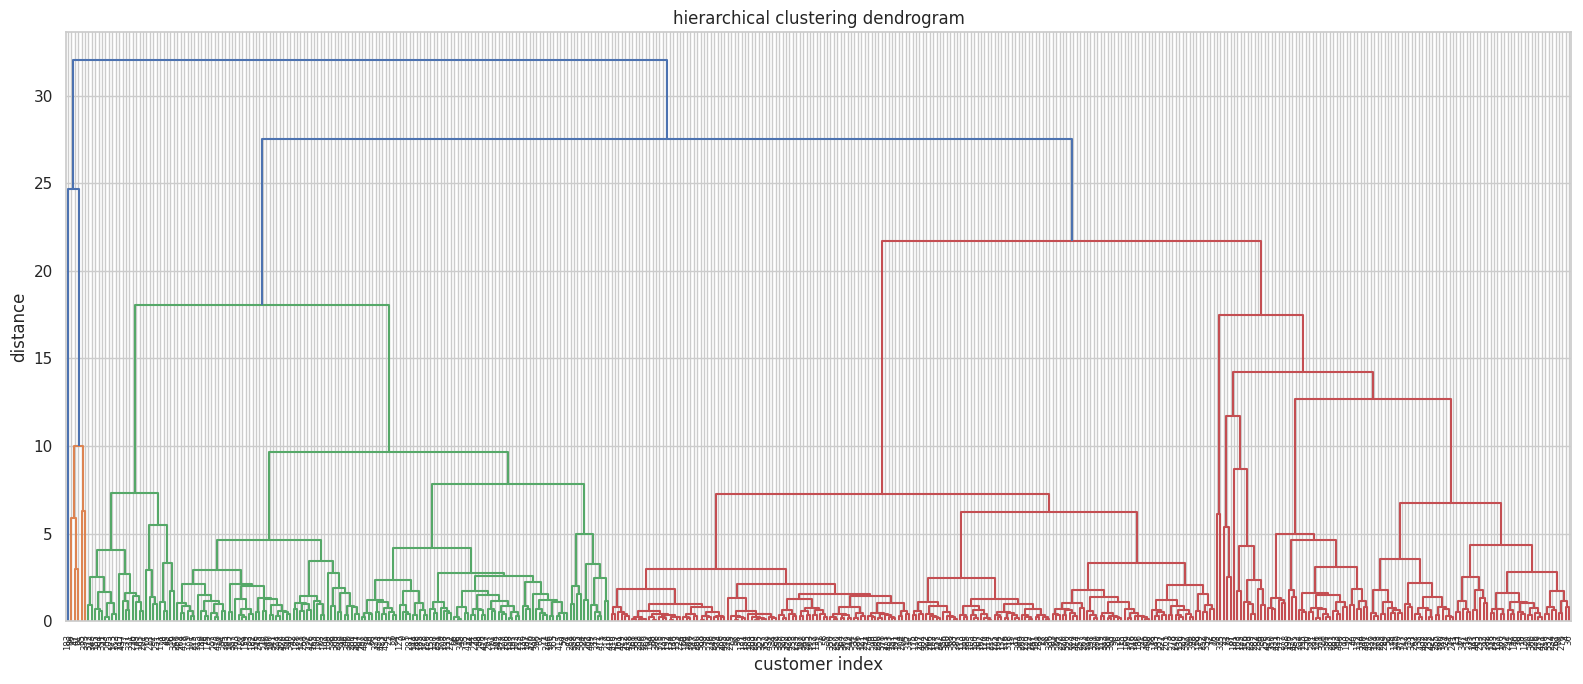

In [ ]:
Z=linkage(X_scaled,method="ward",metric="euclidean")
plt.figure(figsize=(16,7))
dendrogram(Z,leaf_rotation=90,leaf_font_size=6)
plt.title("hierarchical clustering dendrogram")
plt.xlabel("customer index")
plt.ylabel("distance")
plt.tight_layout()
plt.show()

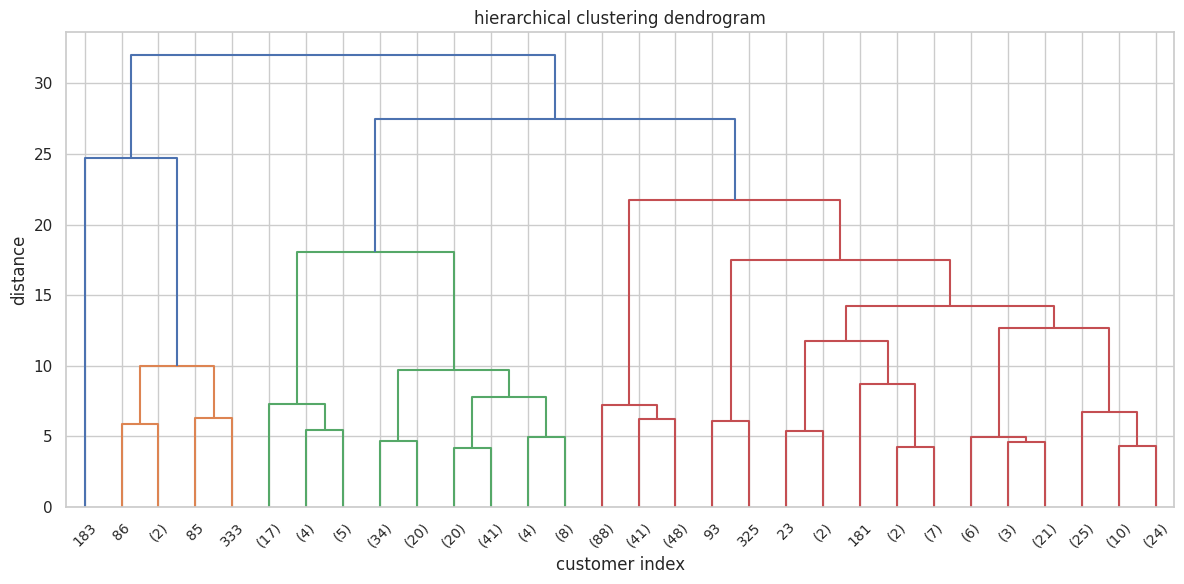

In [ ]:
plt.figure(figsize=(12,6))
dendrogram(Z,truncate_mode="lastp",p=30,show_leaf_counts=True,leaf_rotation=45)
plt.title("hierarchical clustering dendrogram")
plt.xlabel("customer index")
plt.ylabel("distance")
plt.tight_layout()
plt.show()

In [ ]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
print("variance explained by the two PCA components",
      round(pca.explained_variance_ratio_.sum()*100,2),
      "%")
plot_df=pd.DataFrame({"PC1":X_pca[:,0],"PC2":X_pca[:,1],"cluster":kmeans_labels.astype(str),
                      "Hierarchical_cluster":hierarchical_labels.astype(str)})

variance explained by the two PCA components 72.46 %


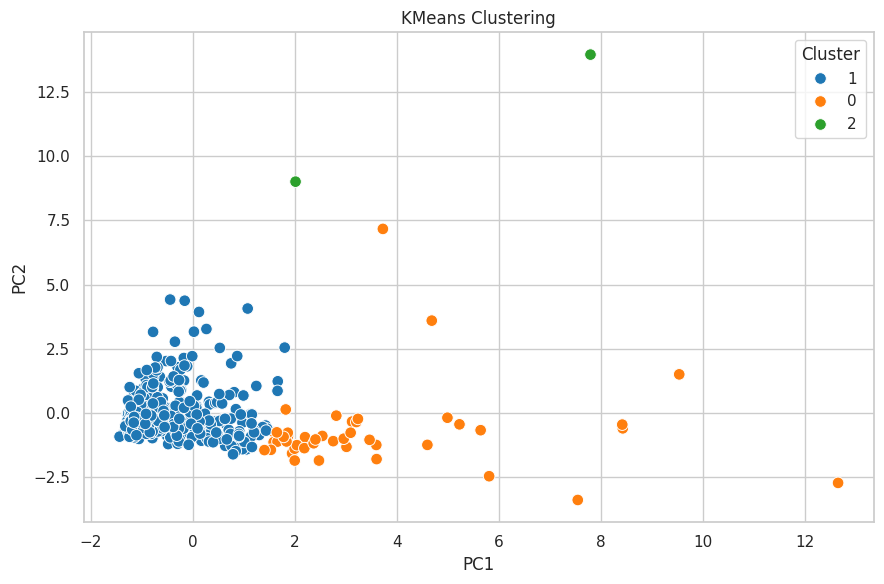

In [ ]:
# K-means visualization
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df,x="PC1",y="PC2",hue="cluster",palette="tab10",s=70)
plt.title("KMeans Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [ ]:
# Function to calculate clustering evaluation metrics
def evaluate_clustering(X_data,labels,model_name):
  return{
      "Algorithm":model_name,
      "Silhouette Score":silhouette_score(X_data,labels),
      "Number of clusters":len(np.unique(labels))
  }

In [ ]:
# evaluate both models using the same scaled features
comparison=pd.DataFrame([
    evaluate_clustering(X_scaled, kmeans_labels, "KMeans"),
    evaluate_clustering(X_scaled, hierarchical_labels, "Hierarchical")
])
display(comparison)

,Algorithm,Silhouette Score,Number of clusters
0,KMeans,0.548287,3
1,Hierarchical,0.264609,3
